In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Statistics:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
# Check for blank spaces in TotalCharges
print("Blank spaces before cleaning:")
print(df["TotalCharges"].str.strip().eq("").sum())

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("\nMissing values after conversion:")
print(df["TotalCharges"].isnull().sum())

# Display the updated data types
print("\nUpdated data types:")
print(df.dtypes)

Blank spaces before cleaning:
11

Missing values after conversion:
11

Updated data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [5]:
# Calculate the median TotalCharges
median_total = df["TotalCharges"].median()

# Fill missing values with the median
df["TotalCharges"] = df["TotalCharges"].fillna(median_total)

# Confirm missing values have been handled
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values:
0


In [6]:
# Check for duplicate rows
print("Number of duplicate rows:")
print(df.duplicated().sum())

# Check for duplicate customer IDs
print("\nNumber of duplicate customer IDs:")
print(df["customerID"].duplicated().sum())

Number of duplicate rows:
0

Number of duplicate customer IDs:
0


In [7]:
# Count customers who stayed and customers who left
print("Customer Churn Distribution:")
print(df["Churn"].value_counts())

# Calculate percentages
print("\nCustomer Churn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


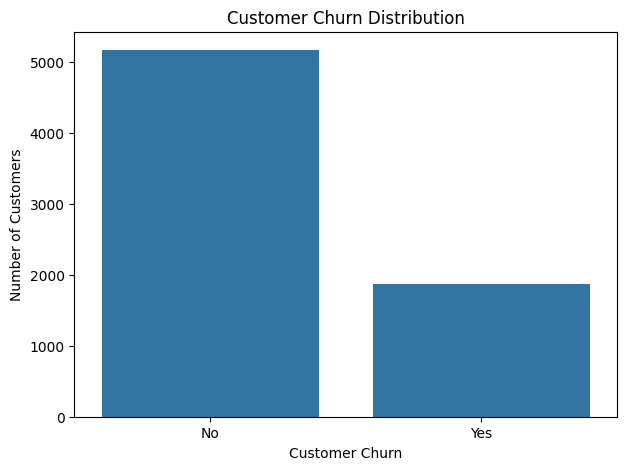

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

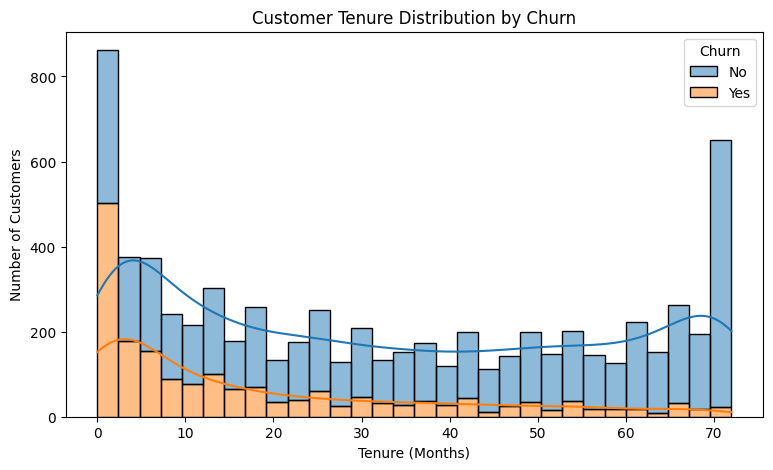

In [9]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

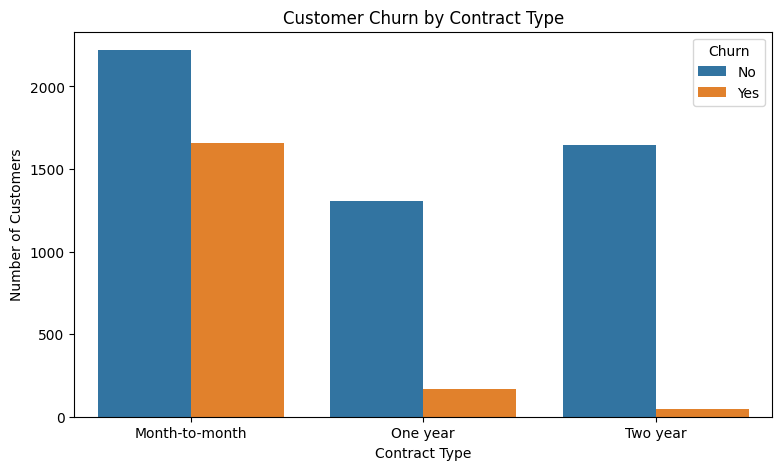

In [10]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

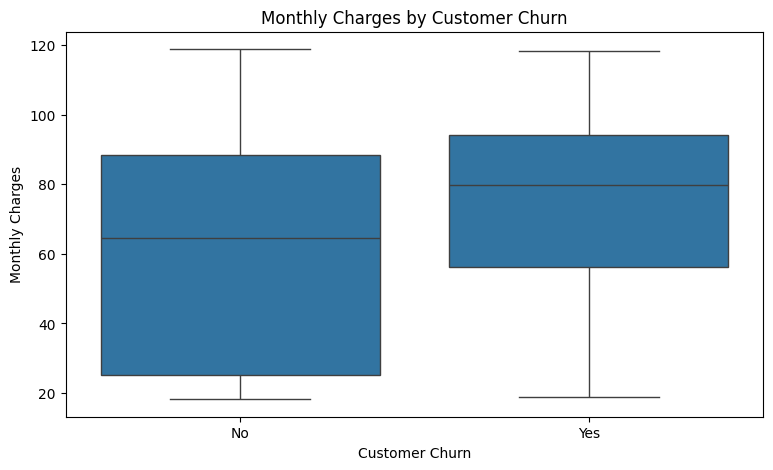

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [12]:
# Remove customerID column
df = df.drop("customerID", axis=1)

# Display remaining columns
print("Updated dataset columns:")
print(df.columns)

print("\nUpdated dataset shape:")
print(df.shape)

Updated dataset columns:
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Updated dataset shape:
(7043, 20)


In [13]:
# Convert Churn into numerical values
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Check the results
print(df["Churn"].value_counts())
print("\nData type:", df["Churn"].dtype)

Churn
0    5174
1    1869
Name: count, dtype: int64

Data type: int64


In [14]:
# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Convert categorical features into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Display the results
print("Encoded dataset shape:", X.shape)

print("\nFirst five rows:")
display(X.head())

Encoded dataset shape: (7043, 30)

First five rows:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (5634, 30)
Testing data shape: (1409, 30)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [17]:
# Create the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

print("Random Forest model created successfully!")


Random Forest model created successfully!


In [18]:
# Train the model using the training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [19]:
# Predict customer churn using the testing data
y_pred = model.predict(X_test)

print("Predictions completed successfully!")

print("\nFirst 20 predictions:")
print(y_pred[:20])

print("\nActual results:")
print(y_test.values[:20])

Predictions completed successfully!

First 20 predictions:
[0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0]

Actual results:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]


In [20]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 78.78 %


In [21]:
# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Left"]
)

print(report)

              precision    recall  f1-score   support

      Stayed       0.83      0.89      0.86      1035
        Left       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



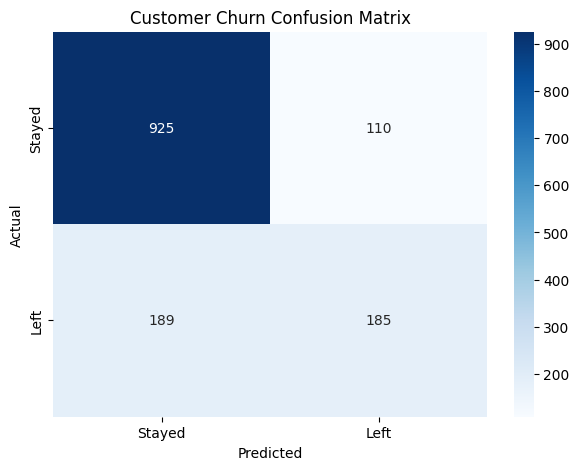

In [22]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Customer Churn Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


Top 10 Important Features:
                           Feature  Importance
3                     TotalCharges    0.174188
1                           tenure    0.166575
2                   MonthlyCharges    0.155530
25               Contract_Two year    0.060160
10     InternetService_Fiber optic    0.038785
28  PaymentMethod_Electronic check    0.034724
13              OnlineSecurity_Yes    0.030879
24               Contract_One year    0.029938
4                      gender_Male    0.025630
26            PaperlessBilling_Yes    0.023959


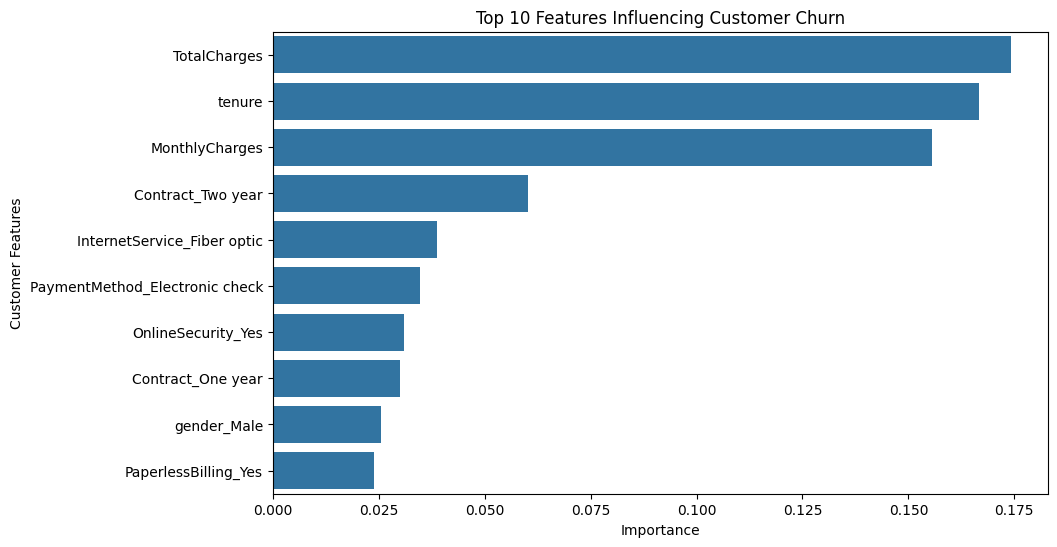

In [23]:
# Extract feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 features
print("Top 10 Important Features:")
print(importance.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Customer Churn")
plt.xlabel("Importance")
plt.ylabel("Customer Features")

plt.show()

In [24]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [25]:
# Create the Logistic Regression model
log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [26]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Scale training and testing features
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create a new Logistic Regression model
log_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Train the model using scaled data
log_model.fit(X_train_scaled, y_train)

print("Scaled Logistic Regression training completed!")

Scaled Logistic Regression training completed!


In [27]:
# Make predictions using the scaled test data
log_pred = log_model.predict(X_test_scaled)

print("First 20 Logistic Regression predictions:")
print(log_pred[:20])

print("\nFirst 20 actual results:")
print(y_test.values[:20])

First 20 Logistic Regression predictions:
[0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 0 0]

First 20 actual results:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]


In [28]:
log_pred = log_model.predict(X_test_scaled)

In [29]:
# Calculate model accuracy
log_accuracy = accuracy_score(y_test, log_pred)

print("Logistic Regression Accuracy:", round(log_accuracy * 100, 2), "%")

# Generate classification report
log_report = classification_report(
    y_test,
    log_pred,
    target_names=["Stayed", "Left"]
)

print("\nLogistic Regression Classification Report:")
print(log_report)

Logistic Regression Accuracy: 73.88 %

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
        Left       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [30]:
# Get classification metrics for both models
rf_report = classification_report(
    y_test, y_pred, output_dict=True
)

lr_report = classification_report(
    y_test, log_pred, output_dict=True
)

# Create comparison table
comparison = pd.DataFrame({
    "Random Forest": [
        accuracy_score(y_test, y_pred),
        rf_report["1"]["precision"],
        rf_report["1"]["recall"],
        rf_report["1"]["f1-score"]
    ],
    "Logistic Regression": [
        accuracy_score(y_test, log_pred),
        lr_report["1"]["precision"],
        lr_report["1"]["recall"],
        lr_report["1"]["f1-score"]
    ]
}, index=["Accuracy", "Churn Precision", "Churn Recall", "Churn F1-score"])

print(comparison.round(3))

                 Random Forest  Logistic Regression
Accuracy                 0.788                0.739
Churn Precision          0.627                0.505
Churn Recall             0.495                0.781
Churn F1-score           0.553                0.613


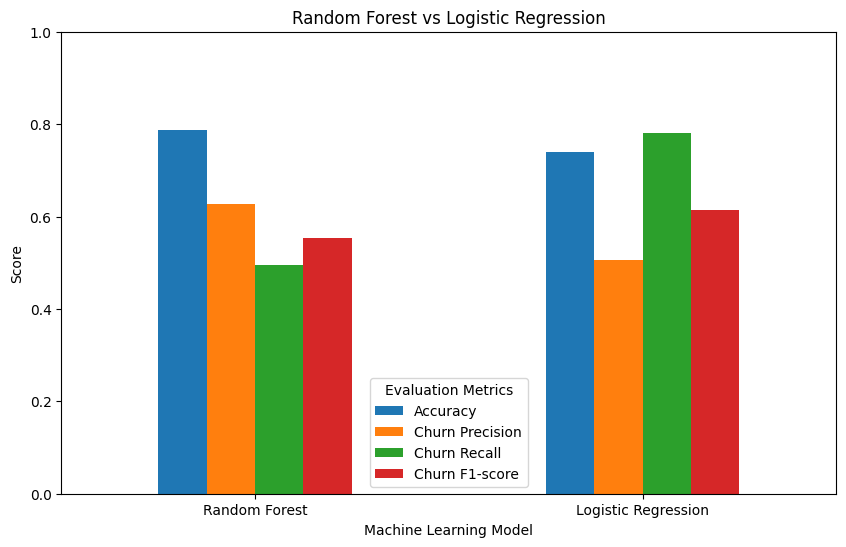

In [31]:
comparison.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Random Forest vs Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.ylim(0, 1)
plt.show()

In [32]:
# Get churn probabilities
log_probabilities = log_model.predict_proba(X_test_scaled)[:, 1]

# Display the first 10 probabilities
print("First 10 churn probabilities:")
print(log_probabilities[:10])

First 10 churn probabilities:
[0.11693709 0.85203414 0.14100542 0.66546792 0.06133097 0.80587338
 0.70040243 0.29385296 0.00896088 0.65238623]


In [33]:
# Set a new classification threshold
threshold = 0.4

# Convert probabilities into predictions
log_pred_04 = (log_probabilities >= threshold).astype(int)

# Evaluate the new predictions
print("Accuracy:", round(accuracy_score(y_test, log_pred_04) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    log_pred_04,
    target_names=["Stayed", "Left"]
))

Accuracy: 69.91 %

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.93      0.64      0.76      1035
        Left       0.46      0.87      0.60       374

    accuracy                           0.70      1409
   macro avg       0.70      0.75      0.68      1409
weighted avg       0.81      0.70      0.72      1409



In [34]:
threshold = 0.3

log_pred_03 = (log_probabilities >= threshold).astype(int)

print("Accuracy:", round(accuracy_score(y_test, log_pred_03) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    log_pred_03,
    target_names=["Stayed", "Left"]
))

Accuracy: 65.15 %

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.95      0.55      0.70      1035
        Left       0.43      0.93      0.58       374

    accuracy                           0.65      1409
   macro avg       0.69      0.74      0.64      1409
weighted avg       0.81      0.65      0.67      1409



  Threshold  Accuracy  Churn Recall  Churn F1-score
0       0.5     0.739         0.781           0.613
1       0.4     0.699         0.866           0.604
2       0.3     0.652         0.925           0.585


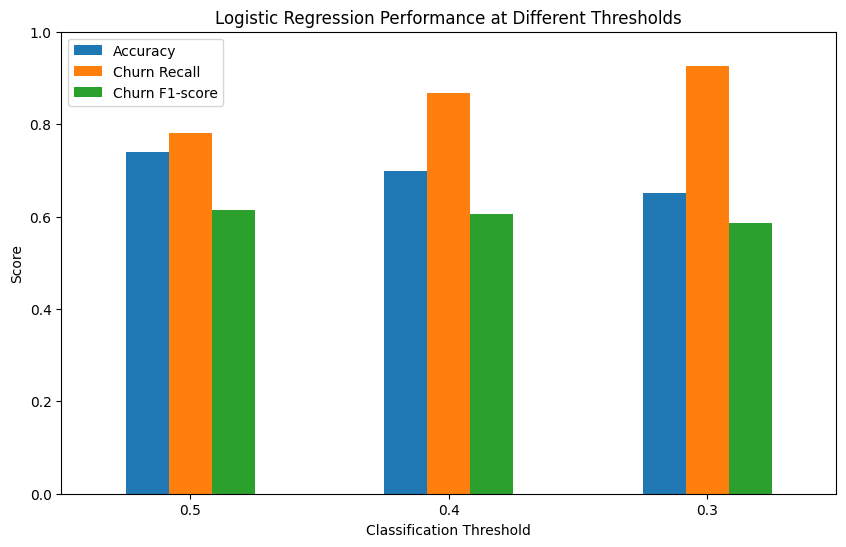

In [38]:
threshold_results = pd.DataFrame({
    "Threshold": ["0.5", "0.4", "0.3"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, log_pred_04),
        accuracy_score(y_test, log_pred_03)
    ],
    "Churn Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, log_pred_04),
        recall_score(y_test, log_pred_03)
    ],
    "Churn F1-score": [
        f1_score(y_test, log_pred),
        f1_score(y_test, log_pred_04),
        f1_score(y_test, log_pred_03)
    ]
})

print(threshold_results.round(3))

threshold_results.set_index("Threshold").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression Performance at Different Thresholds")
plt.ylabel("Score")
plt.xlabel("Classification Threshold")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

In [37]:
from sklearn.metrics import recall_score, f1_score

In [39]:
final_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression (0.5)",
        "Logistic Regression (0.4)",
        "Logistic Regression (0.3)"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, log_pred_04),
        accuracy_score(y_test, log_pred_03)
    ],
    "Churn Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, log_pred),
        recall_score(y_test, log_pred_04),
        recall_score(y_test, log_pred_03)
    ],
    "Churn F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, log_pred),
        f1_score(y_test, log_pred_04),
        f1_score(y_test, log_pred_03)
    ]
})

print(final_results.round(3))

                       Model  Accuracy  Churn Recall  Churn F1-score
0              Random Forest     0.788         0.495           0.553
1  Logistic Regression (0.5)     0.739         0.781           0.613
2  Logistic Regression (0.4)     0.699         0.866           0.604
3  Logistic Regression (0.3)     0.652         0.925           0.585


In [40]:
final_results.to_csv("model_comparison_results.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


## Project Conclusion

This project used machine learning to predict customer churn using the IBM Telco Customer Churn dataset.

Two machine learning algorithms were trained and evaluated: Random Forest and Logistic Regression.

The results showed that Logistic Regression with a 0.5 classification threshold achieved the highest churn F1-score of 0.613, while a threshold of 0.3 achieved the highest churn recall of 0.925.

This demonstrates how adjusting the classification threshold affects a model's ability to identify customers who are likely to leave.

The project provided practical experience in data cleaning, exploratory data analysis, feature encoding, model training, evaluation, and threshold experimentation.